# What Makes a Yelp Review Negative? A Text Analysis of 20,000 Reviews

Star ratings tell you *whether* customers were happy. The text tells you *why*. Using about 20,000 Yelp reviews of 49 businesses (2005–2022), all bakeries, dessert and ice cream shops, I look at:

1. How ratings are distributed, and whether unhappy customers write more.
2. Which words most distinguish 1–2 star reviews from 4–5 star reviews.
3. The most common three-word phrases (trigrams) in each group.
4. How well a simple machine learning model can predict a negative review from its text, and which words drive the prediction.
5. Whether ratings changed over time.

*Data: a sample of Yelp reviews provided in Emory's QTM 151 course materials. I first worked with it there; this analysis is my own. The raw reviews aren't included in this repo because the text belongs to Yelp and its users. See the README for details.*

In [1]:
import re
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25})
NEG, POS = "#dc2626", "#16a34a"

df = pd.read_csv("data/yelp_reviews.csv")
df["date"] = pd.to_datetime(df["date"], format="%m/%d/%Y")
df["review"] = df["review"].fillna("").astype(str)
df["sentiment"] = pd.cut(df.rating, [0, 2, 3, 5], labels=["negative (1–2★)", "neutral (3★)", "positive (4–5★)"])
print(f"{len(df):,} reviews of {df.url.nunique()} businesses, {df.date.min():%Y}–{df.date.max():%Y}")

19,895 reviews of 49 businesses, 2005–2022


## 1. Ratings and review length

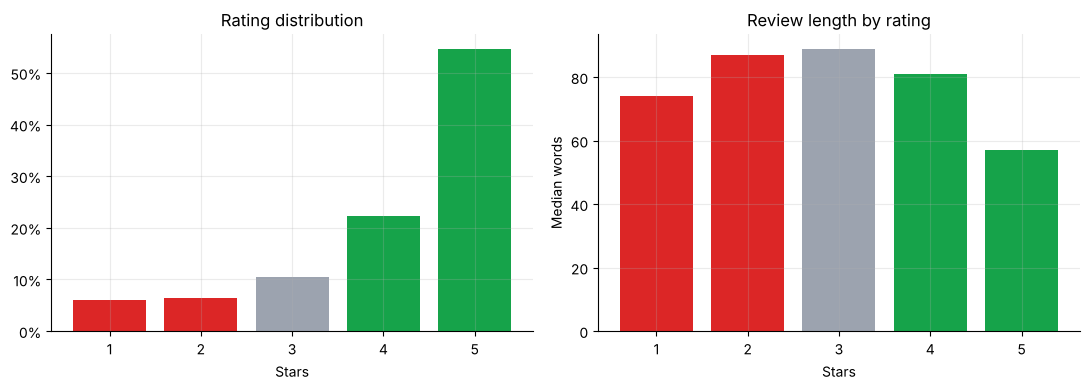

rating,1,2,3,4,5
Share of reviews,6%,6%,10%,22%,55%
Median words,74,87,89,81,57


In [2]:
TOKEN = re.compile(r"[a-z']+")
df["words"] = df.review.str.lower().str.findall(TOKEN)
df["n_words"] = df.words.str.len()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
counts = df.rating.value_counts(normalize=True).sort_index()
a1.bar(counts.index, counts, color=[NEG, NEG, "#9ca3af", POS, POS])
a1.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); a1.set_xlabel("Stars"); a1.set_title("Rating distribution")
med = df.groupby("rating").n_words.median()
a2.bar(med.index, med, color=[NEG, NEG, "#9ca3af", POS, POS])
a2.set_xlabel("Stars"); a2.set_ylabel("Median words"); a2.set_title("Review length by rating")
plt.tight_layout(); plt.savefig("figures/ratings_and_length.png", dpi=150, bbox_inches="tight"); plt.show()
pd.DataFrame({"Share of reviews": counts.map("{:.0%}".format), "Median words": med.astype(int)}).T

## 2. Which words separate negative from positive reviews?
Raw word counts are dominated by words like "food" and "place" that show up everywhere. To find the words that are actually distinctive, I use the **weighted log-odds ratio with an informative Dirichlet prior** (Monroe, Colaresi & Quinn, 2008). It compares how often each word appears in negative vs positive reviews, while shrinking the estimates for rare words so they don't dominate.

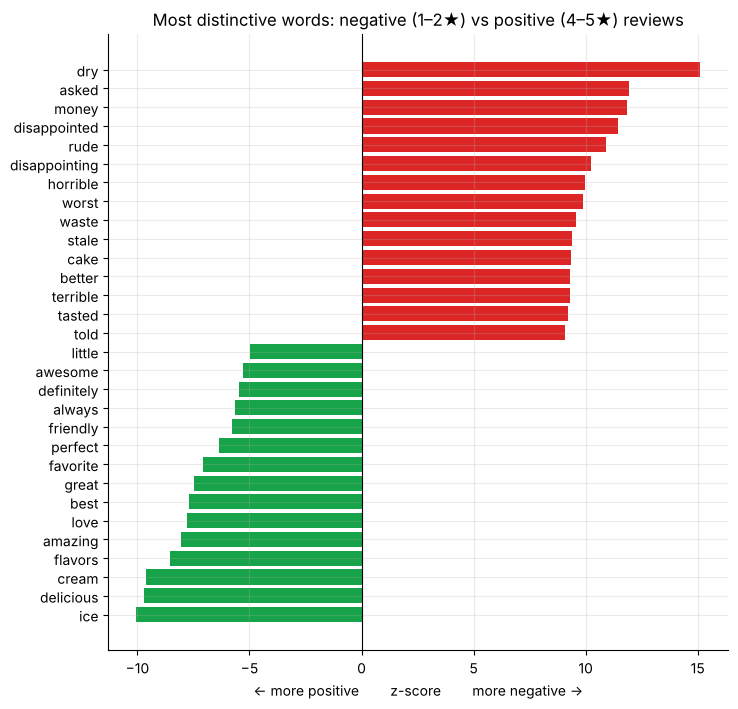

In [3]:
STOP = set('''a about above after again against all am an and any are as at be because been before being below between both
but by can could did do does doing down during each few for from further had has have having he her here hers herself him
himself his how i if in into is it its itself just me more most my myself no nor not of off on once only or other our ours
ourselves out over own same she should so some such than that the their theirs them themselves then there these they this
those through to too under until up very was we were what when where which while who whom why will with would you your yours
yourself yourselves it's i'm i've we're they're don't didn't wasn't isn't can't won't couldn't i'd you're that's there's we've
also get got one us go went said even really back would like'''.split())

def counts_for(mask):
    c = Counter()
    for ws in df.loc[mask, "words"]:
        c.update(w for w in ws if w not in STOP and len(w) > 2)
    return c

neg_c, pos_c = counts_for(df.rating <= 2), counts_for(df.rating >= 4)
vocab = [w for w in set(neg_c) | set(pos_c) if neg_c[w] + pos_c[w] >= 30]
prior = Counter({w: neg_c[w] + pos_c[w] for w in vocab}); a0 = sum(prior.values())
n_neg, n_pos = sum(neg_c[w] for w in vocab), sum(pos_c[w] for w in vocab)

rows = []
for w in vocab:
    yi, yj, aw = neg_c[w], pos_c[w], prior[w]
    d = np.log((yi + aw) / (n_neg + a0 - yi - aw)) - np.log((yj + aw) / (n_pos + a0 - yj - aw))
    var = 1 / (yi + aw) + 1 / (yj + aw)
    rows.append((w, d / np.sqrt(var), yi, yj))
lo = pd.DataFrame(rows, columns=["word", "z", "neg_count", "pos_count"]).set_index("word").sort_values("z")

top_n = 15
show = pd.concat([lo.head(top_n), lo.tail(top_n)])
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(show.index, show.z, color=[POS if z < 0 else NEG for z in show.z])
ax.axvline(0, color="black", lw=.8); ax.set_xlabel("← more positive        z-score        more negative →")
ax.set_title("Most distinctive words: negative (1–2★) vs positive (4–5★) reviews")
plt.savefig("figures/distinctive_words.png", dpi=150, bbox_inches="tight"); plt.show()

## 3. Most common trigrams
Three-word phrases capture context that single words miss, like *"waited for over"* versus *"can't wait to"*. Here I keep stopwords, because phrases like *"the manager said"* depend on them.

In [4]:
def trigram_counts(mask):
    c = Counter()
    for ws in df.loc[mask, "words"]:
        c.update(" ".join(t) for t in zip(ws, ws[1:], ws[2:]))
    return c

def distinctive_trigrams(ca, cb, k=12, min_count=25):
    # trigrams most over-represented in group a vs b (add-one smoothed rate ratio)
    na, nb = sum(ca.values()), sum(cb.values())
    rows = [(t, n, ((n + 1) / na) / ((cb[t] + 1) / nb)) for t, n in ca.items() if n >= min_count]
    out = pd.DataFrame(rows, columns=["trigram", "count", "times more common"])
    return out.sort_values("times more common", ascending=False).head(k).round(1).reset_index(drop=True)

neg3, pos3 = trigram_counts(df.rating <= 2), trigram_counts(df.rating >= 4)
pd.concat({"Negative reviews": distinctive_trigrams(neg3, pos3),
           "Positive reviews": distinctive_trigrams(pos3, neg3)}, axis=1)

Negative reviews                            Positive reviews        \
                  trigram count times more common             trigram count   
0          wanted to like    25             126.7  will definitely be   302   
1   was very disappointed    31              78.0        i can't wait   187   
2     was so disappointed    30              75.6          a must try   168   
3            in the trash    29              73.1          to die for   327   
4         save your money    27              68.2      my favorite is   149   
5           had no flavor    26              65.8  definitely be back   252   
6           won't be back    33              55.2           is a must   246   
7            not worth it    54              53.6  did not disappoint   118   
8              a waste of    26              43.9       can't wait to   345   
9             was dry and    46              38.2      just the right   106   
10          not worth the    92              37.8        the best ice   509   
11          never go back    26              32.9           is to die    99   

                      
   times more common  
0               62.2  
1               38.6  
2               34.7  
3               33.6  
4               30.8  
5               26.0  
6               25.3  
7               24.4  
8               23.7  
9               22.0  
10              20.9  
11              20.5

## 4. Can a model spot a negative review?
I train a **logistic regression on TF-IDF features** (single words and two-word phrases) to classify reviews as negative (1–2★) or positive (4–5★), leaving out 3★ reviews. The data is split 80/20 into train and test sets, stratified by class. Negative reviews are only about 14% of the data, so I use balanced class weights and report precision and recall, not just accuracy.

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score, ConfusionMatrixDisplay

data = df[df.rating != 3]
X_train, X_test, y_train, y_test = train_test_split(data.review, data.rating <= 2, test_size=.2,
                                                    stratify=data.rating <= 2, random_state=42)
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True, stop_words="english")
model = LogisticRegression(max_iter=2000, class_weight="balanced", C=2.0)
model.fit(vec.fit_transform(X_train), y_train)
proba = model.predict_proba(vec.transform(X_test))[:, 1]
pred = proba > .5

print(classification_report(y_test, pred, target_names=["positive", "negative"], digits=3))
print(f"ROC AUC: {roc_auc_score(y_test, proba):.3f}   (baseline of always guessing 'positive': accuracy {1 - y_test.mean():.1%})")

              precision    recall  f1-score   support

    positive      0.983     0.963     0.973      3067
    negative      0.798     0.900     0.846       499

    accuracy                          0.954      3566
   macro avg      0.890     0.931     0.909      3566
weighted avg      0.957     0.954     0.955      3566

ROC AUC: 0.983   (baseline of always guessing 'positive': accuracy 86.0%)


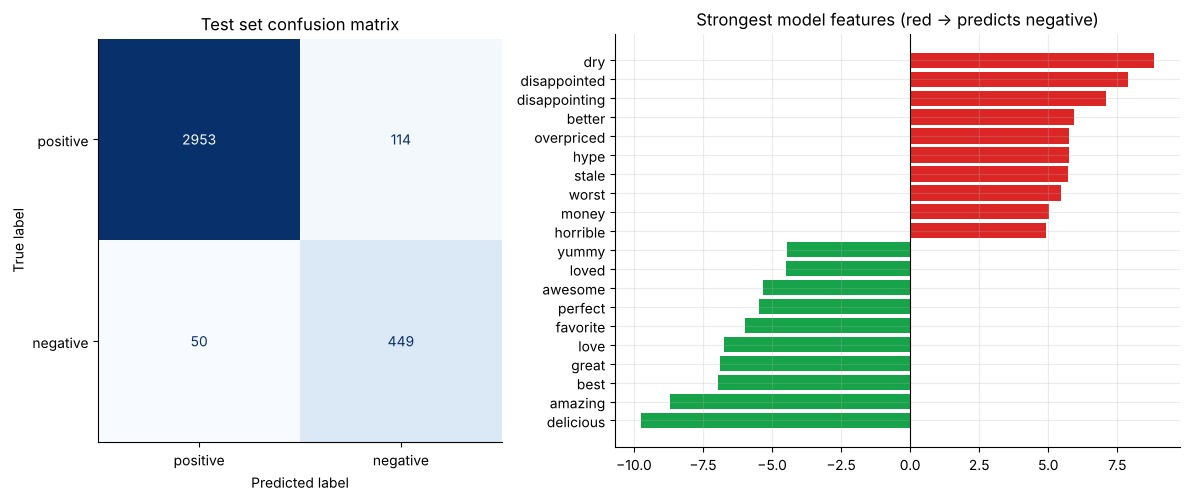

In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1, 1.4]})
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["positive", "negative"], cmap="Blues", ax=a1, colorbar=False)
a1.grid(False); a1.set_title("Test set confusion matrix")
coef = pd.Series(model.coef_[0], index=vec.get_feature_names_out()).sort_values()
top = pd.concat([coef.head(10), coef.tail(10)])
a2.barh(top.index, top, color=[POS if v < 0 else NEG for v in top]); a2.axvline(0, color="black", lw=.8)
a2.set_title("Strongest model features (red → predicts negative)")
plt.tight_layout(); plt.savefig("figures/model.png", dpi=150, bbox_inches="tight"); plt.show()

### Where the model gets it wrong
To see the model's blind spots, I list the misclassified reviews it was most confident about, showing only their length and rating.

In [7]:
errors = pd.DataFrame({"rating": data.loc[X_test.index, "rating"], "p_negative": proba,
                       "words": data.loc[X_test.index, "n_words"]})[pred != y_test]
print(f"{len(errors)} errors out of {len(y_test):,} test reviews")
errors.sort_values("p_negative", key=lambda p: (p - .5).abs(), ascending=False).head(8).round(2)

164 errors out of 3,566 test reviews


,rating,p_negative,words
13420,5,0.99,65
9375,1,0.02,26
4105,4,0.97,81
1377,4,0.94,61
18768,5,0.90,130
10528,5,0.89,264
11260,2,0.11,23
7374,2,0.12,57


## 5. Did ratings change over time?

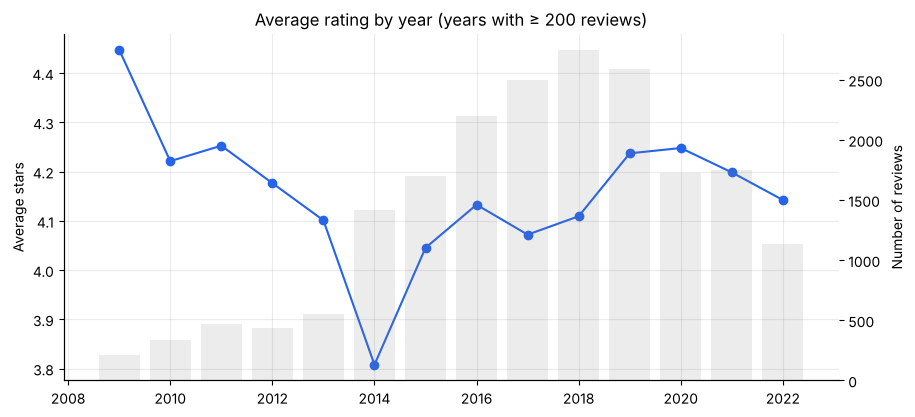

date,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
reviews,210,339,467,436,554,1415,1700,2199,2499,2743,2589,1722,1749,1138
avg,4.45,4.22,4.25,4.18,4.1,3.81,4.05,4.13,4.07,4.11,4.24,4.25,4.2,4.14
neg_share,5%,7%,6%,6%,11%,18%,13%,12%,14%,13%,11%,12%,13%,15%


In [8]:
yearly = df.groupby(df.date.dt.year).agg(reviews=("rating", "size"), avg=("rating", "mean"),
                                         neg_share=("rating", lambda r: (r <= 2).mean()))
yearly = yearly[yearly.reviews >= 200]
fig, ax = plt.subplots()
ax.plot(yearly.index, yearly.avg, marker="o", color="#2563eb")
ax.set_ylabel("Average stars"); ax.set_title("Average rating by year (years with ≥ 200 reviews)")
ax2 = ax.twinx(); ax2.bar(yearly.index, yearly.reviews, alpha=.15, color="grey"); ax2.set_ylabel("Number of reviews")
ax2.grid(False); ax2.spines["top"].set_visible(False)
plt.savefig("figures/ratings_over_time.png", dpi=150, bbox_inches="tight"); plt.show()
yearly.assign(avg=yearly.avg.round(2), neg_share=yearly.neg_share.map("{:.0%}".format)).T

## Takeaways

1. **Ratings are heavily skewed positive.** 55% of reviews are 5 stars and only 12% are 1–2 stars. "Average stars" therefore hides a lot, because most of the signal is in the rare unhappy reviews.
2. **Unhappy customers write more.** The median 2-star review runs 87 words, against 57 words for a 5-star review. People explain what went wrong in detail; happy customers keep it short.
3. **Negative reviews are about product quality, value and staff.** The most distinctive negative words are *dry*, *stale*, *money*, *waste*, *rude* and *asked/told*, the last two being a sign of a bad interaction with staff. Positive reviews talk about flavor and feelings: *delicious*, *amazing*, *love*, *favorite*.
4. **Phrases reveal expectations.** "Wanted to like", "was so disappointed" and "not worth the" (hype) are far more common in negative reviews. "Will definitely be back", "a must try" and "to die for" mark positive ones.
5. **A simple model works well.** TF-IDF plus logistic regression catches **90% of negative reviews** with 80% precision (ROC AUC 0.98). The words it relies on (*dry*, *overpriced*, *hype*, *stale*) closely match the log-odds analysis, so it learned interpretable signals. Its mistakes are mostly mixed reviews, for example a 4–5 star review that complains about one item.
6. **Ratings stayed fairly stable over time,** averaging about 4.1–4.25 in most years. The dip to 3.8 in 2014 came in the same year reviews tripled.

*Limitations:* the 49 businesses are all bakeries and dessert shops, so the vocabulary (*dry*, *stale*, *ice cream*) is specific to that industry. The sample is not a random draw from all of Yelp.